# 27 LSTM: Normalbetrieb lernen, Fehler finden

Teil 6: Lernende Modelle

**Worum es geht**
- Die Kennzahlen aus Notebook 25 sind von Hand ausgewählt. Ein LSTM (neuronales Netz für Zeitreihen mit Gedächtnis) soll aus den Stundenwerten selbst lernen, was eine Station ausmacht, ohne Labels.
- Das Netz liest einen Tag (24 Stunden, sechs Größen) und sagt den nächsten Tag vorher. Dazwischen muss es den Tag in acht Zahlen pressen, das Embedding (kompakte Beschreibung des Tages).
- Das mittlere Embedding einer Station über einen Winter beschreibt die Station. Darauf lernt eine logistische Regression, welche Stationen bei der Begehung einen Befund hatten.
- Vorgabe der Betreuung: Gelernt wird nur auf HAST (Hausanschlussstationen) mit Begehung und nur aus Tagen vor der Begehung. Alle anderen Zähler werden mit dem fertigen Netz nur übersetzt. Zum Vergleich läuft dasselbe Netz einmal auf allen Zählern (Abschnitt 5).

**Daten**
- liest: `data/processed/modell_stunden.parquet`, `modell_labels.csv`, `modell_kennzahlen.csv`
- schreibt: `data/processed/lstm_embedding.csv` (Embeddings je Zähler), `data/processed/lstm_scores.csv` (Vorhersagen aus der Prüfung), Modellgewichte in `notebooks/models/`
- vorher ausführen: Notebook 25

**Code**
- Netz und Prüfung stehen im Notebook. Die Labels stammen aus der Freitextkodierung in `src/befundcodes.py`.

## 1 Ausgangslage und Setup

### 1.1 Warum ein LSTM

- Das LSTM ist das Ergebnis vieler Versuche. Die Zahlen sind AUC-Werte gegen die Befunde der Begehungen, gemessen in der lokalen Vorarbeit auf 52 bis 53 begangenen Stationen.
- AUC = Wahrscheinlichkeit, dass eine Station mit Befund vor einer ohne Befund eingeordnet wird (0,5 = Raten, 1 = perfekt).

| Versuch | Ventil | Dämmung | Warum es nicht gereicht hat |
|---|---|---|---|
| Anomalie-Score gegen die ganze Flotte (robuste Kovarianz) | 0,81 | 0,45 | findet extreme Stationen, nur das Ventil, nicht die Dämmung |
| Regel „nachts im Sommer nie still“ | 0,87–0,91 | 0,48 | stark fürs Ventil, aber nur im Sommer und nur für dieses Fehlerbild |
| Rücklauf bei 0 °C (wetterbereinigt) | 0,76 | 0,24 | Rücklauf allein sagt zu wenig, bei der Dämmung sogar verkehrt herum |
| Logistische Regression auf 9 Kennzahlen | 0,87 | 0,75 | gut, aber man muss die Kennzahlen kennen; im Winter fehlt das Ventilsignal |
| LSTM-Autoencoder („Tag nachbilden“) | 0,88 | 0,68 | lernt das Typische eines Tages, zu wenig über die Station |
| **LSTM „nächsten Tag vorhersagen“** | 0,89 | 0,76 | gewählt: muss lernen, wie die Station auf Wetter und Vortag reagiert |
| Suche über 24 Varianten (LSTM, GRU, 1D-CNN; Größe; Kern) | 0,85–0,88 | 0,69–0,78 | die Aufgabe entscheidet, nicht der Netztyp (Abschnitt 5) |
| Embedding + Nachbarn im Leitungsgraphen (Graph-Netz) | 0,89 | 0,66 | Nachbarn bringen nichts, die Fehler sitzen im einzelnen Haus |


Was daraus folgt:
- Unüberwacht allein reicht nicht. Die Suche nach Ungewöhnlichem findet große Abnehmer und Messfehler, nicht die Fehler.
- Ein großes Netz direkt auf die Labels zu trainieren, wurde nicht versucht. Bei 11 Ventilfällen und über 100.000 Gewichten würde es die Fälle auswendig lernen.
- Deshalb zwei Stufen: Das LSTM lernt ohne Labels aus zehntausenden Tagen. Erst danach nutzt eine einfache logistische Regression die 53 Labels.

### 1.2 Setup

- Lädt PyTorch für das Netz und scikit-learn für die Prüfung.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, LeaveOneOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
MODELLE = ROOT / "notebooks" / "models"
MODELLE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

STICHTAG = pd.Timestamp("2024-09-01")
NEU_TRAINIEREN = False      #True: Gewichte neu lernen
SEED = 0
torch.manual_seed(SEED)
GERAET = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, gerechnet auf: {GERAET}")

PyTorch 2.15.0, gerechnet auf: cpu


- `NEU_TRAINIEREN = False`: Liegen schon Gewichte in `notebooks/models/`, werden sie geladen statt neu gelernt.
- Der Ordner ist nicht im Git (gitignored). Auf einem neuen Rechner wird beim ersten Lauf also immer trainiert.
- Gerechnet wird auf der Grafikkarte (GPU), falls vorhanden, sonst auf der CPU, nur langsamer.

## 2 Daten laden und ansehen

- Lädt die drei Dateien aus Notebook 25: Stundenwerte, Labels und Kennzahlen.

In [2]:
stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
kz = pd.read_csv(PROCESSED / "modell_kennzahlen.csv", index_col="zaehler")
print(f"stunden: {stunden.shape[0]:,} Zeilen × {stunden.shape[1]} Spalten, {stunden['zaehler'].nunique()} Zähler")
print(f"labels:  {labels.shape[0]} begangene Zähler, kz: {kz.shape[0]} Zähler × {kz.shape[1]} Kennzahlen")
stunden.dropna().sample(5, random_state=SEED).sort_values(["zaehler", "timestamp"])

stunden: 2,128,400 Zeilen × 8 Spalten, 93 Zähler
labels:  56 begangene Zähler, kz: 91 Zähler × 16 Kennzahlen


,zaehler,timestamp,vorlauf,ruecklauf,spreizung,durchfluss,leistung,aussen
12366,53198226,2023-04-01 05:00:00,63.8,55.9,7.9,0.0,0.00,9.8
261149,68956344,2024-12-04 17:00:00,68.4,58.6,9.7,242.0,2.77,3.1
320762,68956347,2024-05-07 10:00:00,72.5,41.0,31.5,0.0,0.00,12.3
617238,68956361,2024-06-27 09:00:00,55.7,46.4,9.3,0.0,0.00,20.8
1736256,80912172,2024-12-27 23:00:00,42.7,41.5,1.1,0.0,0.00,-3.2


- 93 Zähler in den Stundenwerten, 56 begangene Zähler mit Label, Kennzahlen für 91 Zähler.
- Die fünf Beispielzeilen zeigen das Rohmaterial des Netzes: je Stunde Vorlauf, Rücklauf, Spreizung (Vorlauf minus Rücklauf), Durchfluss, Leistung und Außentemperatur.

### 2.1 Vollständige Tage als Feld

- Das Netz liest ganze Tage. Jeder vollständige Tag wird eine Tabelle mit 24 Zeilen (Stunden) und 6 Spalten (Größen).
- Alle Tage zusammen ergeben ein dreidimensionales Feld: Tage × 24 × 6.

In [3]:
KANAELE = ["leistung", "durchfluss", "spreizung", "vorlauf", "ruecklauf", "aussen"]
stunden = stunden.dropna(subset=KANAELE)
stunden["tag"] = stunden["timestamp"].dt.floor("D")
voll = stunden.groupby(["zaehler", "tag"])["timestamp"].transform("size") == 24
stunden = stunden[voll].sort_values(["zaehler", "timestamp"])

werte = stunden[KANAELE].to_numpy(dtype=np.float32).reshape(-1, 24, len(KANAELE))
tage = stunden[["zaehler", "tag"]].iloc[::24].reset_index(drop=True)

#je Zähler: bis wann gilt "vor der Begehung" und ist er begangen?
grenze = labels["erste_begehung"].clip(upper=STICHTAG)
tage["vorher"] = tage["tag"] < tage["zaehler"].map(grenze).fillna(STICHTAG)
tage["begangen"] = tage["zaehler"].isin(labels.index)
print(f"Feld: {werte.shape[0]:,} Tage × {werte.shape[1]} Stunden × {werte.shape[2]} Größen")
pd.crosstab(tage["begangen"].map({True: "begangene HAST", False: "nie begangen"}),
            tage["vorher"].map({True: "vor der Begehung", False: "danach"}), margins=True, margins_name="Summe")

Feld: 67,840 Tage × 24 Stunden × 6 Größen


vorher,danach,vor der Begehung,Summe
begangen,,,
begangene HAST,17568,24684,42252
nie begangen,9781,15807,25588
Summe,27349,40491,67840


- Stunden mit fehlenden Werten fallen weg. Es bleiben nur Tage mit allen 24 Stunden, zusammen 67.840 Tage.
- `reshape(-1, 24, 6)` baut das Feld. Das klappt, weil die Tabelle nach Zähler und Zeit sortiert ist und je 24 Zeilen einen Tag bilden.
- `tage` merkt sich je Tag Zähler und Datum, ob der Tag vor der ersten Begehung liegt und ob der Zähler begangen wurde.
- Die Kreuztabelle zeigt, woraus das Netz lernen darf: begangene HAST vor der Begehung (24.684 Tage).

### 2.2 Skalierung

- Netze lernen schlecht, wenn eine Größe in Hunderten (Durchfluss) und eine andere in Zehnern (Temperatur) gemessen wird.
- Leistung und Durchfluss werden je Zähler durch sein 95-%-Quantil geteilt. So sieht gleiches Verhalten bei großen und kleinen Häusern gleich aus.
- Temperaturen und Spreizung werden für alle gleich standardisiert (Mittelwert abziehen, durch Streuung teilen). 65 °C Rücklauf ist in jedem Haus schlecht, das soll das Netz sehen.
- Die Skalen kommen nur aus Tagen vor den Begehungen. Für nie begangene Zähler wird ihr eigenes 95-%-Quantil genauso bestimmt, damit das Netz sie übersetzen kann.

In [4]:
x = werte.copy()
vorher = tage["vorher"].to_numpy()
stunde_vorher = np.repeat(vorher, 24)          #dieselbe Markierung je Stunde
teiler, mittel, streuung, skalen = {}, {}, {}, {}
for i, kanal in enumerate(KANAELE):
    if kanal in ("leistung", "durchfluss"):
        teiler[kanal] = stunden[stunde_vorher].groupby("zaehler")[kanal].quantile(0.95).clip(lower=1e-3)
        je_tag = tage["zaehler"].map(teiler[kanal]).fillna(1.0).to_numpy(dtype=np.float32)
        x[:, :, i] = werte[:, :, i] / je_tag[:, None]
        skalen[kanal] = "Wert / 95-%-Quantil des Zählers"
    else:
        mittel[kanal], streuung[kanal] = werte[vorher, :, i].mean(), werte[vorher, :, i].std()
        x[:, :, i] = (werte[:, :, i] - mittel[kanal]) / streuung[kanal]
        skalen[kanal] = f"(Wert − {mittel[kanal]:.1f}) / {streuung[kanal]:.1f}"
pd.DataFrame({"Skalierung": pd.Series(skalen),
              "Mittel danach": pd.Series(x[vorher].mean(axis=(0, 1)), index=KANAELE).round(2),
              "Streuung danach": pd.Series(x[vorher].std(axis=(0, 1)), index=KANAELE).round(2)})

,Skalierung,Mittel danach,Streuung danach
leistung,Wert / 95-%-Quantil des Zählers,0.27,0.37
durchfluss,Wert / 95-%-Quantil des Zählers,0.35,0.40
spreizung,(Wert − 15.9) / 13.6,-0.00,1.00
vorlauf,(Wert − 63.2) / 15.5,-0.00,1.00
ruecklauf,(Wert − 47.3) / 15.8,0.00,1.00
aussen,(Wert − 11.7) / 8.3,0.00,1.00


- Nach dem Teilen liegen typische Werte für Leistung und Durchfluss zwischen 0 und 1.
- Die Tabelle zeigt die Rechnung je Größe und prüft das Ergebnis: Temperaturen und Spreizung haben danach Mittel 0 und Streuung 1.

### 2.3 Lernbeispiele: heute und morgen

- Ein Lernbeispiel ist ein Paar aus zwei aufeinanderfolgenden vollständigen Tagen desselben Zählers. Das Netz bekommt heute komplett und von morgen nur die Außentemperatur; die steht im Wetterbericht, das Verhalten der Station nicht.
- Für den Vergleich in Abschnitt 5 gibt es zwei weitere Varianten: dieselbe Aufgabe auf allen Zählern und „Tag nachbilden“ (Autoencoder: Ein- und Ausgabe sind derselbe Tag).
- `beispiele()` stellt für jede Variante die passenden Tage zusammen.
- Validiert wird auf ganzen Kalenderwochen. Der 14. Januar einer Station gleicht dem 13. fast genau; einzelne Tage in der Validierung würden die Prüfung zu leicht machen.

In [5]:
folgetag = ((tage["zaehler"].shift(-1) == tage["zaehler"])
            & (tage["tag"].shift(-1) == tage["tag"] + pd.Timedelta(days=1))).to_numpy()


def beispiele(nur_begangene, aufgabe):
    #Eingangs- und Zieltage je Variante, dazu die Validierungswochen
    erlaubt = vorher & (tage["begangen"].to_numpy() if nur_begangene else True)
    if aufgabe == "vorhersagen":
        heute = np.flatnonzero(folgetag & erlaubt & np.roll(erlaubt, -1))
        ziel_tag = heute + 1
    else:  #nachbilden: Eingang und Ziel sind derselbe Tag
        heute = np.flatnonzero(erlaubt)
        ziel_tag = heute
    woche = tage.loc[ziel_tag, "tag"].dt.to_period("W").astype(str).to_numpy()
    wochen = np.unique(woche)
    val_wochen = np.random.default_rng(SEED).choice(wochen, size=int(0.1 * len(wochen)), replace=False)
    return heute, ziel_tag, np.isin(woche, val_wochen)


VARIANTEN = {
    "begangen":    {"nur_begangene": True,  "aufgabe": "vorhersagen", "text": "nächsten Tag vorhersagen, nur begangene HAST (Hauptmodell)"},
    "alle":        {"nur_begangene": False, "aufgabe": "vorhersagen", "text": "nächsten Tag vorhersagen, alle HAST"},
    "nachbilden":  {"nur_begangene": True,  "aufgabe": "nachbilden",  "text": "Tag nachbilden (Autoencoder), nur begangene HAST"},
}
zeilen = []
for name, v in VARIANTEN.items():
    heute, ziel_tag, ist_val = beispiele(v["nur_begangene"], v["aufgabe"])
    zeilen.append({"Variante": name, "Beschreibung": v["text"], "Beispiele": len(heute),
                   "davon Validierung": int(ist_val.sum()), "Zähler": tage.loc[heute, "zaehler"].nunique()})
pd.DataFrame(zeilen).set_index("Variante")

,Beschreibung,Beispiele,davon Validierung,Zähler
Variante,,,,
begangen,"nächsten Tag vorhersagen, nur begangene HAST (...",24236,1987,54
alle,"nächsten Tag vorhersagen, alle HAST",39711,3318,90
nachbilden,"Tag nachbilden (Autoencoder), nur begangene HAST",24684,1999,54


- `folgetag` ist wahr, wenn der nächste Eintrag derselbe Zähler am nächsten Kalendertag ist. Nur dann gibt es ein echtes Paar.
- `beispiele()` nimmt nur Tage vor der Begehung, beim Hauptmodell nur von begangenen Zählern, und legt 10 % der Kalenderwochen als Validierung fest.
- Hauptmodell: 24.236 Beispiele von 54 Zählern, gegen 39.711 von 90 Zählern bei „alle“. Dafür nur Stationen, deren Zustand durch die Begehung bekannt ist.

## 3 Das Netz

```
heute (24 × 6) ──► LSTM-Encoder (96) ──► 8 Zahlen = Embedding
                                              │
          Außentemperatur morgen (24 × 1) ──► LSTM-Decoder (96) ──► morgen (24 × 5)
```

- Der Encoder liest den Tag Stunde für Stunde und fasst ihn in seinem letzten Zustand zusammen. Eine lineare Schicht presst das auf acht Zahlen.
- Der Decoder bekommt diese acht Zahlen zu jeder Stunde des Zieltags, dazu die Außentemperatur dieser Stunde, und gibt fünf Größen aus.
- Beim Autoencoder ist der Zieltag derselbe Tag.

In [6]:
class LSTMEmbedding(nn.Module):
    def __init__(self, n_ein=6, n_aus=5, versteckt=96, kern=8):
        super().__init__()
        self.encoder = nn.LSTM(n_ein, versteckt, batch_first=True)
        self.zum_kern = nn.Linear(versteckt, kern)
        self.vom_kern = nn.Linear(kern, versteckt)
        self.decoder = nn.LSTM(versteckt + 1, versteckt, batch_first=True)
        self.ausgang = nn.Linear(versteckt, n_aus)

    def einbetten(self, tag):
        _, (zustand, _) = self.encoder(tag)
        return self.zum_kern(zustand[-1])

    def forward(self, tag, aussen_ziel):
        kern = self.einbetten(tag)
        je_stunde = self.vom_kern(kern).unsqueeze(1).repeat(1, aussen_ziel.shape[1], 1)
        y, _ = self.decoder(torch.cat([je_stunde, aussen_ziel], dim=2))
        return self.ausgang(y)


print(LSTMEmbedding())
print(f"{sum(p.numel() for p in LSTMEmbedding().parameters()):,} lernbare Gewichte")

LSTMEmbedding(
  (encoder): LSTM(6, 96, batch_first=True)
  (zum_kern): Linear(in_features=96, out_features=8, bias=True)
  (vom_kern): Linear(in_features=8, out_features=96, bias=True)
  (decoder): LSTM(97, 96, batch_first=True)
  (ausgang): Linear(in_features=96, out_features=5, bias=True)
)
116,941 lernbare Gewichte


- Das Netz besteht aus zwei `nn.LSTM` und drei `nn.Linear`, zusammen 116.941 lernbare Gewichte.
- `einbetten()` liefert die acht Zahlen. Nach dem Training wird nur diese Funktion gebraucht, um jeden Tag zu übersetzen.
- `forward()` ist der ganze Weg vom Eingangstag zum Zieltag und dient nur dem Lernen.

## 4 Training des Hauptmodells (nur begangene HAST)

- Gelernt wird mit dem Adam-Optimierer auf den mittleren quadratischen Fehler.
- Nach jeder Runde durch alle Trainingsbeispiele wird der Fehler auf der Validierung gemessen.
- Early Stopping: Wird der Fehler 20 Runden lang nicht besser, ist Schluss, und der beste Stand bleibt. Stagniert er 5 Runden, wird die Lernrate halbiert.

In [7]:
def trainieren(heute, ziel_tag, ist_val, max_runden=300, geduld=20, stapel=512):
    torch.manual_seed(SEED)
    modell = LSTMEmbedding().to(GERAET)
    opt = torch.optim.Adam(modell.parameters(), lr=3e-3)
    plan = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5, min_lr=1e-5)
    e = torch.tensor(x[heute]).to(GERAET)
    z = torch.tensor(x[ziel_tag][:, :, :5]).to(GERAET)
    a = torch.tensor(x[ziel_tag][:, :, 5:]).to(GERAET)
    lern, val = np.flatnonzero(~ist_val), torch.tensor(np.flatnonzero(ist_val), device=GERAET)
    verlauf, bester, bester_zustand, ohne_besserung = [], np.inf, None, 0
    for runde in range(max_runden):
        modell.train()
        summe = 0.0
        for teil in np.array_split(np.random.default_rng(runde).permutation(lern), max(1, len(lern) // stapel)):
            i = torch.tensor(teil, device=GERAET)
            verlust = nn.functional.mse_loss(modell(e[i], a[i]), z[i])
            opt.zero_grad()
            verlust.backward()
            opt.step()
            summe += verlust.item() * len(teil)
        modell.eval()
        with torch.no_grad():
            v = nn.functional.mse_loss(modell(e[val], a[val]), z[val]).item()
        verlauf.append({"runde": runde + 1, "training": summe / len(lern), "validierung": v})
        plan.step(v)
        if v < bester - 1e-5:
            bester, ohne_besserung = v, 0
            bester_zustand = {k: w.detach().clone() for k, w in modell.state_dict().items()}
        else:
            ohne_besserung += 1
            if ohne_besserung >= geduld:
                break
    modell.load_state_dict(bester_zustand)
    return modell, pd.DataFrame(verlauf)


def laden_oder_trainieren(name):
    datei = MODELLE / f"lstm_embedding_{name}.pt"
    v = VARIANTEN[name]
    heute, ziel_tag, ist_val = beispiele(v["nur_begangene"], v["aufgabe"])
    if datei.exists() and not NEU_TRAINIEREN:
        modell = LSTMEmbedding().to(GERAET)
        gespeichert = torch.load(datei, map_location=GERAET)
        modell.load_state_dict(gespeichert["gewichte"])
        verlauf = pd.DataFrame(gespeichert["verlauf"])
        print(f"{name:11s} Gewichte geladen aus {datei.relative_to(ROOT)}")
    else:
        start = time.time()
        modell, verlauf = trainieren(heute, ziel_tag, ist_val)
        torch.save({"gewichte": modell.state_dict(), "verlauf": verlauf.to_dict("list")}, datei)
        print(f"{name:11s} trainiert in {time.time() - start:.0f} s, gespeichert in {datei.relative_to(ROOT)}")
    modell.eval()
    return modell, verlauf, (heute, ziel_tag, ist_val)


modell, verlauf, (heute, ziel_tag, ist_val) = laden_oder_trainieren("begangen")
beste_runde = int(verlauf.loc[verlauf["validierung"].idxmin(), "runde"])
print(f"{len(verlauf)} Runden, bester Validierungsfehler {verlauf['validierung'].min():.4f} in Runde {beste_runde}")

begangen    trainiert in 352 s, gespeichert in notebooks/models/lstm_embedding_begangen.pt
85 Runden, bester Validierungsfehler 0.1778 in Runde 65


- `trainieren()` ist die übliche PyTorch-Schleife: Stapel von 512 Beispielen durchs Netz schicken, Fehler berechnen, `backward()`, `step()`. Nach jeder Runde wird der beste Stand gemerkt.
- `laden_oder_trainieren()` lädt gespeicherte Gewichte oder trainiert neu. Die Lernkurve wird mitgespeichert, damit ein zweiter Lauf dieselbe Kurve zeigt.
- Ergebnis: rund 6 Minuten Training auf der CPU, 85 Runden, bester Validierungsfehler 0,1778 in Runde 65.

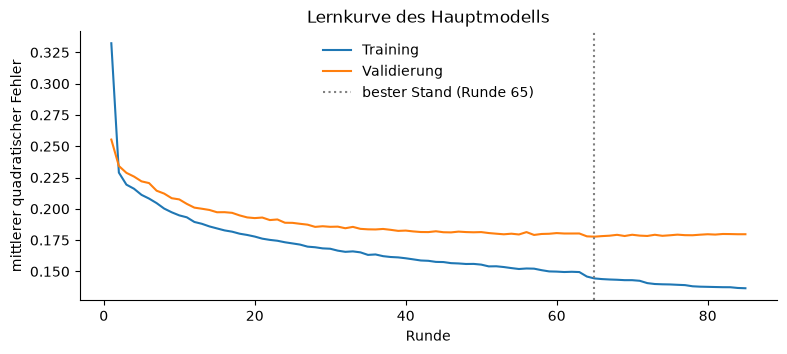

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(verlauf["runde"], verlauf["training"], label="Training")
ax.plot(verlauf["runde"], verlauf["validierung"], label="Validierung")
ax.axvline(beste_runde, color="grey", ls=":", label=f"bester Stand (Runde {beste_runde})")
ax.set_xlabel("Runde")
ax.set_ylabel("mittlerer quadratischer Fehler")
ax.set_title("Lernkurve des Hauptmodells")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

- Die Lernkurve zeigt, wie der Fehler über die Runden sinkt. Laufen Training und Validierung weit auseinander, lernt das Netz die Trainingstage auswendig (Überanpassung).

- Der Validierungsfehler fällt in den ersten 20 Runden steil und wird ab etwa Runde 40 flach.
- Bester Stand in Runde 65. Nach 20 Runden ohne Besserung bricht das Training in Runde 85 ab.
- Danach sinkt nur noch der Trainingsfehler. Ab hier würde das Netz anfangen, die Trainingstage auswendig zu lernen.
- Das Training dauert auf der CPU rund 6 Minuten (auf einer GPU rund 11 Sekunden). Kürzer als bei „alle HAST“ (9 Minuten), weil nur die begangenen HAST gelernt werden (24.236 statt 39.711 Beispiele).

Validierungsfehler je Tag: Median 0.141; gezeigt wird ein Wintertag mit 0.121


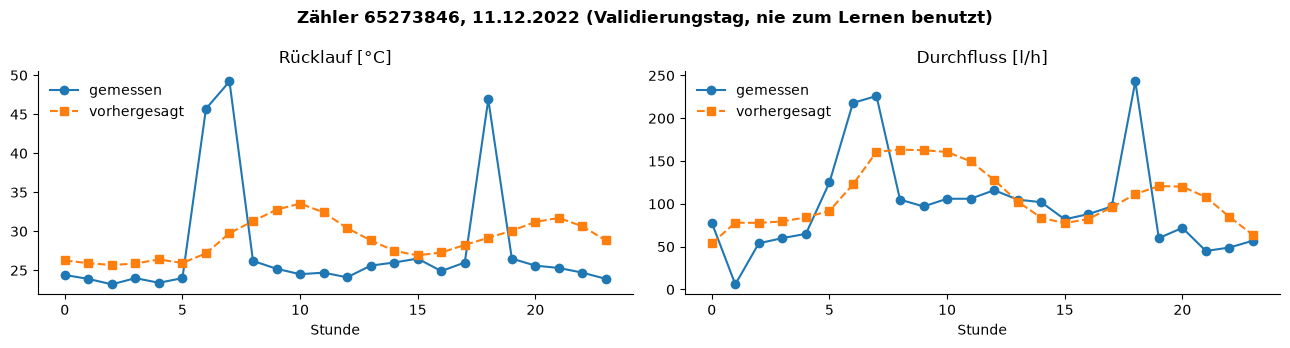

In [9]:
#typischer Validierungstag im Winter (mittlerer Fehler)
val_index = np.flatnonzero(ist_val)
with torch.no_grad():
    val_vorhersage = modell(torch.tensor(x[heute[val_index]]).to(GERAET),
                            torch.tensor(x[ziel_tag[val_index]][:, :, 5:]).to(GERAET)).cpu().numpy()
fehler_je_tag = ((val_vorhersage - x[ziel_tag[val_index]][:, :, :5]) ** 2).mean(axis=(1, 2))
im_winter = tage.loc[ziel_tag[val_index], "tag"].dt.month.isin([12, 1, 2]).to_numpy()
kandidaten = np.flatnonzero(im_winter)
mitte = kandidaten[np.argsort(fehler_je_tag[kandidaten])[len(kandidaten) // 2]]
vorhersage, tag_index = val_vorhersage[mitte], ziel_tag[val_index[mitte]]
print(f"Validierungsfehler je Tag: Median {np.median(fehler_je_tag):.3f}; gezeigt wird ein Wintertag mit {fehler_je_tag[mitte]:.3f}")
zaehler, datum = tage.loc[tag_index, "zaehler"], tage.loc[tag_index, "tag"]
i_rl, i_fl = KANAELE.index("ruecklauf"), KANAELE.index("durchfluss")
rl_vorh = vorhersage[:, i_rl] * streuung["ruecklauf"] + mittel["ruecklauf"]
fl_vorh = vorhersage[:, i_fl] * teiler["durchfluss"][zaehler]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(werte[tag_index, :, i_rl], "o-", label="gemessen")
axes[0].plot(rl_vorh, "s--", label="vorhergesagt")
axes[0].set_title("Rücklauf [°C]")
axes[1].plot(werte[tag_index, :, i_fl], "o-", label="gemessen")
axes[1].plot(fl_vorh, "s--", label="vorhergesagt")
axes[1].set_title("Durchfluss [l/h]")
for ax in axes:
    ax.set_xlabel("Stunde")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Zähler {zaehler}, {datum:%d.%m.%Y} (Validierungstag, nie zum Lernen benutzt)", fontweight="bold")
fig.tight_layout()
plt.show()

- Sagt alle Validierungstage vorher und zeigt unter den Wintertagen den mit dem mittleren Fehler: kein Glanzbeispiel, kein Ausreißer (Fehler 0,121, Median aller Validierungstage 0,141).
- Die Skalierung wird zurück in °C und l/h gerechnet.
- Das Netz soll den groben Verlauf treffen, nicht jede Stunde. Für das Embedding zählt, dass es das Typische einer Station erfasst.

## 5 Embeddings, Wiedererkennung und Vergleich der drei Varianten

- Ab jetzt wird nur der Encoder gebraucht. Jeder vollständige Tag wird in seine acht Zahlen übersetzt, auch Tage nie begangener Zähler.
- Je Zähler und Zeitraum beschreibt der Mittelwert über alle Tage die Station.
- Die Wiedererkennung prüft ohne Labels, ob diese Beschreibung taugt: Liegt das Winter-Embedding 23/24 einer Station ihrem eigenen von 22/23 am nächsten? Raten träfe bei n Stationen in 1/n der Fälle.

In [10]:
ZEITRAEUME = {"w2223": ("2022-10-01", "2023-04-01"), "w2324": ("2023-10-01", "2024-04-01"), "s2024": ("2024-06-01", "2024-09-01")}
MIN_TAGE = 30


def embeddings(modell):
    with torch.no_grad():
        kerne = torch.cat([modell.einbetten(torch.tensor(x[i:i + 4096]).to(GERAET)).cpu()
                           for i in range(0, len(x), 4096)]).numpy()
    kern_tab = pd.concat([tage[["zaehler", "tag", "vorher"]], pd.DataFrame(kerne, columns=[f"z{i}" for i in range(8)])], axis=1)
    teile = []
    for name, (von, bis) in ZEITRAEUME.items():
        t = kern_tab[(kern_tab["tag"] >= von) & (kern_tab["tag"] < bis) & kern_tab["vorher"]]
        m = t.groupby("zaehler")[[f"z{i}" for i in range(8)]].mean()
        teile.append(m[t.groupby("zaehler").size() >= MIN_TAGE].add_prefix(f"lstm_{name}_"))
    return pd.concat(teile, axis=1)


def wiedererkennung(emb):
    beide = emb[[f"lstm_w2223_z{i}" for i in range(8)] + [f"lstm_w2324_z{i}" for i in range(8)]].dropna()
    alt, neu = beide.filter(like="w2223").to_numpy(), beide.filter(like="w2324").to_numpy()
    abstand = np.linalg.norm(neu[:, None, :] - alt[None, :, :], axis=2)   #Station i (23/24) gegen Station j (22/23)
    rang = pd.Series((abstand < np.diag(abstand)[:, None]).sum(axis=1) + 1, index=beide.index)
    return rang                                                          #1 = die eigene Station ist die nächste


embedding = embeddings(modell)
rang = wiedererkennung(embedding)
print(f"Embeddings für {len(embedding)} Zähler; je Zeitraum vorhanden: "
      + ", ".join(f"{n} {embedding[f'lstm_{n}_z0'].notna().sum()}" for n in ZEITRAEUME))
gruppe = rang.index.isin(labels.index)
print(f"Wiedererkennung über zwei Winter: {(rang == 1).mean():.0%} von {len(rang)} Stationen (Zufall {1 / len(rang):.0%})")
print(f"  begangene HAST (im Training):  {(rang[gruppe] == 1).mean():.0%} von {gruppe.sum()}")
print(f"  nie begangene (nie gesehen):    {(rang[~gruppe] == 1).mean():.0%} von {(~gruppe).sum()}")
embedding.round(2).head()

Embeddings für 90 Zähler; je Zeitraum vorhanden: w2223 41, w2324 87, s2024 82
Wiedererkennung über zwei Winter: 85% von 41 Stationen (Zufall 2%)
  begangene HAST (im Training):  87% von 23
  nie begangene (nie gesehen):    83% von 18


,lstm_w2223_z0,lstm_w2223_z1,lstm_w2223_z2,lstm_w2223_z3,lstm_w2223_z4,lstm_w2223_z5,lstm_w2223_z6,lstm_w2223_z7,lstm_w2324_z0,lstm_w2324_z1,lstm_w2324_z2,lstm_w2324_z3,lstm_w2324_z4,lstm_w2324_z5,lstm_w2324_z6,lstm_w2324_z7,lstm_s2024_z0,lstm_s2024_z1,lstm_s2024_z2,lstm_s2024_z3,lstm_s2024_z4,lstm_s2024_z5,lstm_s2024_z6,lstm_s2024_z7
zaehler,,,,,,,,,,,,,,,,,,,,,,,,
53198226,-0.39,0.16,-0.28,0.26,-0.25,0.10,-0.03,-0.92,-0.09,-0.12,-0.17,0.36,-0.32,0.20,-0.28,-1.17,-0.52,0.46,-0.33,-0.41,0.38,-0.1,0.32,-0.68
58177363,-0.18,-0.07,0.16,0.67,-0.52,0.15,-0.30,-0.83,-0.05,-0.01,0.16,0.58,-0.48,0.13,-0.13,-0.84,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
58177384,-0.29,0.04,-0.71,0.03,0.19,-0.02,-0.75,-0.91,-0.07,0.01,-0.32,-0.27,-0.23,-0.06,-0.28,-0.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
61620222,-0.20,0.11,-0.06,0.48,-0.10,-0.17,0.10,0.04,-0.08,0.06,0.07,0.48,-0.27,-0.17,0.15,0.12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65273846,0.54,-0.66,1.09,0.38,-1.11,-0.23,-0.18,-0.26,0.41,-0.45,1.18,0.18,-1.05,-0.07,0.14,0.07,0.02,0.43,0.94,-0.20,-0.59,0.2,0.62,0.95


- `embeddings()` übersetzt alle Tage mit `modell.einbetten()` und mittelt je Zähler über drei Zeiträume: Winter 22/23, Winter 23/24, Sommer 2024. Nur Tage vor der Begehung, nur bei mindestens 30 Tagen.
- `wiedererkennung()` misst den Abstand jedes 23/24-Embeddings zu allen 22/23-Embeddings und zählt, wie viele fremde Stationen näher liegen als die eigene.
- Getrennt ausgewiesen: Stationen aus dem Training und nie begangene, die das Netz nie gesehen hat. Für diese ist die Wiedererkennung ein echter Test.

- 85 % der 41 Stationen mit zwei Wintern werden wiedererkannt: Ihr Embedding 23/24 liegt dem eigenen von 22/23 näher als jedem fremden. Zufall wären 2 %.
- Auch nie begangene Stationen werden meist erkannt: 83 % von 18, gegen 87 % von 23 bei den begangenen. Der Abstand entspricht etwa einer Station.
- Das passt dazu, dass das Netz allgemein gelernt hat, wie sich eine Station verhält, und nicht die begangenen Stationen auswendig.
- Die Vorgabe der Betreuung ist hier kein Nachteil: Das Netz aus den begangenen HAST beschreibt auch die anderen.

### 5.1 Vorgabe und Alternativen im direkten Vergleich

- Dieselbe Rechnung für die beiden anderen Varianten.
- Jede Variante wird gleich geprüft: Wiedererkennung ohne Labels und die verschachtelte Fehlererkennung aus Abschnitt 6, nur mit den Embeddings.

In [11]:
def verschachtelt(X, y, gruppen=None):
    #Vorhersage je Station aus einem Modell, das sie nie gesehen hat
    pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             LogisticRegression(class_weight="balanced", max_iter=5000))
    suche = GridSearchCV(pipeline, {"logisticregression__C": [0.03, 0.1, 0.3, 1.0]},
                         cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc")
    aussen = LeaveOneOut() if gruppen is None else LeaveOneGroupOut()
    return cross_val_predict(suche, X, y, cv=aussen, groups=gruppen, method="predict_proba", n_jobs=-1)[:, 1]


def auc_mit_intervall(y, score, n=2000):
    y, score = np.asarray(y), np.asarray(score)
    rng = np.random.default_rng(SEED)
    ziehungen = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            ziehungen.append(roc_auc_score(y[i], score[i]))
    return roc_auc_score(y, score), np.quantile(ziehungen, 0.025), np.quantile(ziehungen, 0.975)


def precision_at_k(y, score, k=10):
    return np.asarray(y)[np.argsort(-np.asarray(score))[:k]].mean()


LSTM_WINTER = [f"lstm_w2324_z{i}" for i in range(8)]
LSTM_SOMMER = [f"lstm_s2024_z{i}" for i in range(8)]
alle_embeddings = {"begangen": embedding}
for name in ("alle", "nachbilden"):
    m, verl, _ = laden_oder_trainieren(name)
    alle_embeddings[name] = embeddings(m)

#gleiche Prüfbasis für alle Varianten
basis_index = labels.index.intersection(kz.dropna(subset=["sommer_durchlauf_anteil"]).index)
for emb in alle_embeddings.values():
    basis_index = basis_index.intersection(emb.dropna(subset=LSTM_WINTER).index)

zeilen = []
for name, emb in alle_embeddings.items():
    r = wiedererkennung(emb)
    zeile = {"Variante": name, "Beschreibung": VARIANTEN[name]["text"], "Wiedererkennung": (r == 1).mean()}
    for ziel in ("ventil", "daemmung"):
        y = labels.loc[basis_index, ziel].astype(int).to_numpy()
        for satz, spalten in (("Winter", LSTM_WINTER), ("Winter+Sommer", LSTM_WINTER + LSTM_SOMMER)):
            zeile[f"{ziel} ({satz})"] = roc_auc_score(y, verschachtelt(emb.loc[basis_index, spalten], y))
    zeilen.append(zeile)
varianten_vergleich = pd.DataFrame(zeilen).set_index("Variante")
print(f"Prüfbasis: {len(basis_index)} begangene Zähler, gleich für alle drei Varianten")
varianten_vergleich.round(2)

alle        trainiert in 536 s, gespeichert in notebooks/models/lstm_embedding_alle.pt


nachbilden  trainiert in 703 s, gespeichert in notebooks/models/lstm_embedding_nachbilden.pt


Prüfbasis: 53 begangene Zähler, gleich für alle drei Varianten


,Beschreibung,Wiedererkennung,ventil (Winter),ventil (Winter+Sommer),daemmung (Winter),daemmung (Winter+Sommer)
Variante,,,,,,
begangen,"nächsten Tag vorhersagen, nur begangene HAST (...",0.85,0.82,0.85,0.69,0.74
alle,"nächsten Tag vorhersagen, alle HAST",0.90,0.85,0.86,0.65,0.71
nachbilden,"Tag nachbilden (Autoencoder), nur begangene HAST",0.73,0.77,0.88,0.69,0.71


- Definiert die Prüfwerkzeuge, die auch Abschnitt 6 braucht: `verschachtelt()` (verschachtelte Kreuzvalidierung), `auc_mit_intervall()` und `precision_at_k()`.
- Lädt oder trainiert die zwei Vergleichsvarianten und prüft alle drei gleich, auf denselben 53 begangenen Zählern.
- AUC für Ventil und Dämmung aus den Embeddings allein, einmal nur Winter, einmal Winter und Sommer.

| Variante | Wiedererkennung | Ventil (Winter) | Ventil (Winter+Sommer) | Dämmung (Winter) | Dämmung (Winter+Sommer) |
|---|---|---|---|---|---|
| Vorhersagen, nur begangene HAST (Vorgabe) | 0,85 | 0,82 | 0,85 | 0,69 | 0,74 |
| Vorhersagen, alle HAST | 0,90 | 0,85 | 0,86 | 0,65 | 0,71 |
| Tag nachbilden (Autoencoder) | 0,73 | 0,77 | 0,88 | 0,69 | 0,71 |

- Bei den AUC-Werten liegen alle drei Varianten im selben Bereich. Die Unterschiede von 0,01 bis 0,08 sind kleiner als die Unsicherheit bei 11 Ventil- und 22 Dämmungsfällen (Intervalle jeweils rund ±0,15). Wer die Variante nach der besten AUC wählt, passt sie den Befunden an.
- Die Wiedererkennung entscheidet und spricht gegen den Autoencoder: 0,73 gegen 0,85 bis 0,90. Er beschreibt den einzelnen Tag gut, die Station schlechter. Dasselbe zeigte die lokale Suche über 24 Varianten (0,74 gegen 0,87).
- Die Vorgabe „nur begangene HAST“ kostet nichts Messbares: Wiedererkennung 0,85 gegen 0,90 (zwei der 41 Stationen) bei rund 40 % weniger Lernbeispielen.
- Beim Ventil liegt sie im Winter 0,03 und mit Winter und Sommer 0,01 tiefer, bei der Dämmung 0,03 bis 0,04 höher. Das liegt im Rauschen.

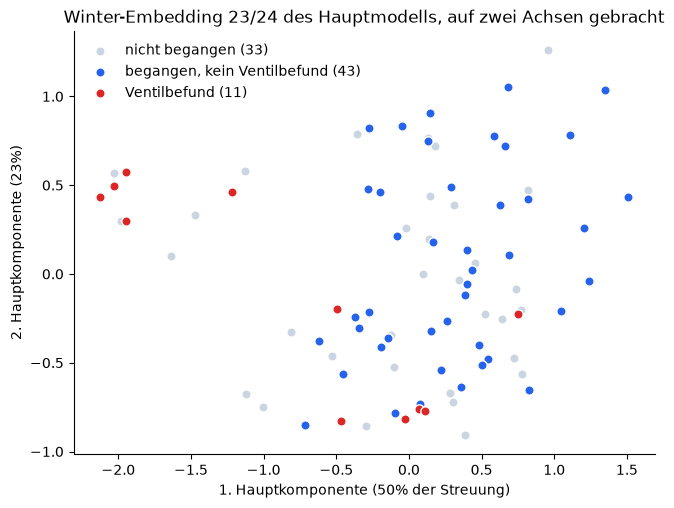

In [12]:
w = embedding.filter(like="lstm_w2324_").dropna()
pca = PCA(n_components=2).fit(w)
punkte = pd.DataFrame(pca.transform(w), index=w.index, columns=["pc1", "pc2"]).join(labels["ventil"])
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for wert, farbe, name in ((np.nan, "#CBD5E1", "nicht begangen"), (False, "#2563EB", "begangen, kein Ventilbefund"), (True, "#DC2626", "Ventilbefund")):
    teil = punkte[punkte["ventil"].isna()] if wert is np.nan else punkte[punkte["ventil"] == wert]
    ax.scatter(teil["pc1"], teil["pc2"], color=farbe, s=45, label=f"{name} ({len(teil)})", edgecolor="white")
ax.set_xlabel(f"1. Hauptkomponente ({pca.explained_variance_ratio_[0]:.0%} der Streuung)")
ax.set_ylabel(f"2. Hauptkomponente ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Winter-Embedding 23/24 des Hauptmodells, auf zwei Achsen gebracht")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

- Acht Zahlen kann man nicht zeichnen. Die Hauptkomponentenanalyse (PCA) sucht die zwei Richtungen, in denen die Stationen am stärksten streuen, und zeigt die Stationen darin.
- Gefärbt nach Ventilbefund. Diese Farben hat das Netz nie gesehen.

- Links (1. Hauptkomponente unter −1) sitzt eine eigene Gruppe: 5 der 11 Ventilfälle, keine begangene Station ohne Befund und 7 nie begangene Stationen (grau).
- Diese sieben sind erste Kandidaten. Notebook 29 rechnet das mit einem Modell nach.
- Die übrigen 6 Ventilfälle liegen in der Mitte zwischen den anderen. Für sie reichen zwei Achsen nicht.
- Die beiden Achsen fassen 73 % der Streuung der acht Zahlen.

## 6 Fehlererkennung: Welche Station hatte bei der Begehung einen Befund?

- Jetzt kommen die Labels, mit dem Hauptmodell. Auf den Embeddings lernt eine logistische Regression, ob eine Station einen Ventil- oder Dämmungsbefund hatte.
- Verschachtelte Kreuzvalidierung: Außen wird jede Station einmal ausgelassen (Leave-one-out). Innen wählt eine 4-fache Kreuzvalidierung nur auf den übrigen Stationen die Regularisierung `C`. Die ausgelassene Station beeinflusst weder Modell noch `C`.
- AUC mit 95-%-Intervall aus 2000 Bootstrap-Ziehungen (Stationen zufällig mit Zurücklegen neu ziehen). Dazu Precision@10: Wie viele der zehn am höchsten eingestuften Stationen hatten wirklich einen Befund? Das ist die Praxisfrage „Welche zehn begehe ich zuerst?“.
- Zur Vorgabe: Das Netz hat Tage der hier geprüften Stationen gesehen, aber nie ihre Labels und nie Tage nach ihrer Begehung. Die Labels kommen erst in der verschachtelt geprüften Regression vor.

In [13]:
KENNZAHLEN = [c for c in kz.columns if not c.startswith("stunden_") and c != "auslastung_vertrag"]
WINTER_KZ = [c for c in KENNZAHLEN if c.startswith("winter_") or c in ("auslastung", "anteil_volumenstrom", "streubreite_betriebspunkte", "ruecklauf_lastgewichtet")]

tabelle = labels[["ventil", "daemmung", "strasse_gruppe"]].join(kz).join(embedding)
basis = tabelle.dropna(subset=LSTM_WINTER + ["sommer_durchlauf_anteil"])
print(f"Prüfbasis: {len(basis)} begangene Zähler mit Winter-Embedding und Sommerwerten "
      f"(Ventil {int(basis['ventil'].sum())}, Dämmung {int(basis['daemmung'].sum())})")
print(f"Ausgeschlossen: {len(labels) - len(basis)} begangene Zähler ohne genug Winter- oder Sommertage")

VERFAHREN = {
    "Kennzahlen (alle)": KENNZAHLEN,
    "LSTM Winter + Sommer": LSTM_WINTER + LSTM_SOMMER,
    "Kennzahlen + LSTM": KENNZAHLEN + LSTM_WINTER + LSTM_SOMMER,
    "nur Winter: Kennzahlen": WINTER_KZ,
    "nur Winter: LSTM": LSTM_WINTER,
    "nur Winter: Kennzahlen + LSTM": WINTER_KZ + LSTM_WINTER,
}
scores = {}
for ziel in ("ventil", "daemmung"):
    y = basis[ziel].astype(int).to_numpy()
    scores[(ziel, "Sommernacht-Regel (ohne Lernen)")] = basis["sommer_durchlauf_anteil"].to_numpy()
    for name, spalten in VERFAHREN.items():
        scores[(ziel, name)] = verschachtelt(basis[spalten], y)

zeilen = []
for (ziel, name), s in scores.items():
    y = basis[ziel].astype(int).to_numpy()
    auc, unten, oben = auc_mit_intervall(y, s)
    zeilen.append({"Ziel": ziel, "Verfahren": name, "AUC": auc, "unten": unten, "oben": oben, "P@10": precision_at_k(y, s)})
ergebnis = pd.DataFrame(zeilen)
ergebnis.round(2)

Prüfbasis: 53 begangene Zähler mit Winter-Embedding und Sommerwerten (Ventil 11, Dämmung 22)
Ausgeschlossen: 3 begangene Zähler ohne genug Winter- oder Sommertage


,Ziel,Verfahren,AUC,unten,oben,P@10
0,ventil,Sommernacht-Regel (ohne Lernen),0.85,0.68,0.98,0.7
1,ventil,Kennzahlen (alle),0.79,0.57,0.97,0.6
2,ventil,LSTM Winter + Sommer,0.85,0.72,0.95,0.6
3,ventil,Kennzahlen + LSTM,0.89,0.77,0.97,0.7
4,ventil,nur Winter: Kennzahlen,0.68,0.44,0.89,0.5
5,ventil,nur Winter: LSTM,0.82,0.68,0.94,0.5
6,ventil,nur Winter: Kennzahlen + LSTM,0.79,0.61,0.94,0.6
7,daemmung,Sommernacht-Regel (ohne Lernen),0.57,0.40,0.73,0.6
8,daemmung,Kennzahlen (alle),0.69,0.53,0.84,0.9
9,daemmung,LSTM Winter + Sommer,0.74,0.59,0.86,0.8


- Merkmalsgruppen: Kennzahlen aus Notebook 25, LSTM-Embeddings aus Winter und Sommer, beides zusammen und drei Varianten nur mit Winterdaten.
- Die Prüfbasis ist für alle Verfahren gleich: 53 begangene Zähler mit Winter-Embedding und Sommerwerten (Ventil 11, Dämmung 22). Sonst wären die AUC-Werte nicht vergleichbar.
- Messlatte ohne Lernen ist die Sommernacht-Regel: Stationen nach dem Anteil der Sommernächte mit Durchfluss sortieren.
- `auslastung_vertrag` bleibt draußen. Sie ist nur für begangene Zähler bekannt und gehört zur Überdimensionierung (Notebook 29).

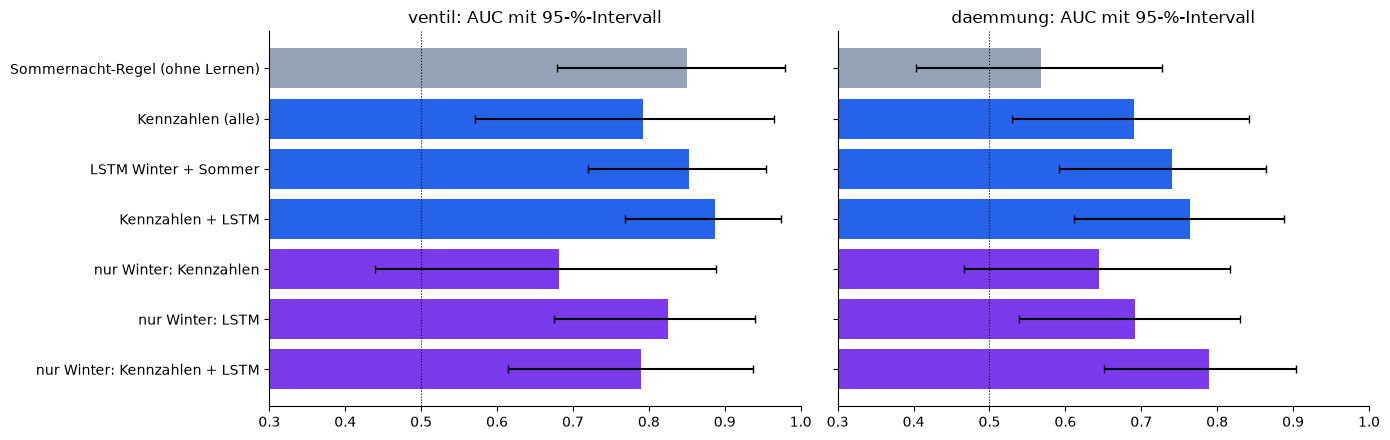

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for ax, ziel in zip(axes, ("ventil", "daemmung")):
    t = ergebnis[ergebnis["Ziel"] == ziel].reset_index(drop=True)
    farben = ["#94A3B8" if "Regel" in v else "#7C3AED" if v.startswith("nur Winter") else "#2563EB" for v in t["Verfahren"]]
    ax.barh(t["Verfahren"], t["AUC"], xerr=[t["AUC"] - t["unten"], t["oben"] - t["AUC"]], color=farben, capsize=3)
    ax.axvline(0.5, color="black", lw=0.8, ls=":")
    ax.set_xlim(0.3, 1.0)
    ax.invert_yaxis()
    ax.set_title(f"{ziel}: AUC mit 95-%-Intervall")
    ax.spines[["top", "right"]].set_visible(False)
axes[1].set_yticklabels([])
fig.tight_layout()
plt.show()

- AUC je Verfahren mit Bootstrap-Intervall. Grau: Regel ohne Lernen, blau: mit Sommerdaten, violett: nur Winterdaten. Die gepunktete Linie ist Raten.

Hauptmodell (nur begangene HAST):
- Ventil (11 von 53, Basisrate 21 %) mit Sommerdaten: Die Regel ohne Lernen erreicht 0,85, Kennzahlen und LSTM zusammen 0,89 [0,77; 0,97].
- Ventil nur mit Winterdaten: Kennzahlen 0,68, LSTM 0,82, beides 0,79. Das LSTM liegt vorne, aber mit breitem Intervall (0,68 bis 0,94).
- Dämmung (22 von 53, Basisrate 42 %): Die Sommernacht-Regel sagt nichts (0,57). Das passt, sie misst das Ventil.
- Dämmung mit Lernen: Kennzahlen 0,69, LSTM 0,74, beides 0,76; nur Winter, beides zusammen 0,79. Unter den zehn höchsten Stationen haben mit Kennzahlen 9 einen Dämmungsbefund (Zufall: 4).

### 6.1 Ist der Unterschied belegt?

- Zwei AUC-Werte mit überlappenden Intervallen können trotzdem verschieden sein, weil beide auf denselben Stationen gemessen werden.
- Richtig ist der gepaarte Vergleich: In jeder Bootstrap-Ziehung werden beide Verfahren auf derselben Stichprobe bewertet und die Differenz gemerkt.
- Schließt das 95-%-Intervall der Differenz die 0 aus, gilt der Unterschied als belegt.

In [15]:
def auc_differenz(y, a, b, n=2000):
    rng = np.random.default_rng(SEED)
    differenzen = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            differenzen.append(roc_auc_score(y[i], a[i]) - roc_auc_score(y[i], b[i]))
    return roc_auc_score(y, a) - roc_auc_score(y, b), np.quantile(differenzen, 0.025), np.quantile(differenzen, 0.975)


VERGLEICHE = [
    ("ventil", "nur Winter: LSTM", "nur Winter: Kennzahlen"),
    ("ventil", "nur Winter: LSTM", "Sommernacht-Regel (ohne Lernen)"),
    ("ventil", "Kennzahlen + LSTM", "Sommernacht-Regel (ohne Lernen)"),
    ("ventil", "Kennzahlen + LSTM", "Kennzahlen (alle)"),
    ("daemmung", "Kennzahlen + LSTM", "Kennzahlen (alle)"),
    ("daemmung", "nur Winter: LSTM", "nur Winter: Kennzahlen"),
]
zeilen = []
for ziel, a, b in VERGLEICHE:
    y = basis[ziel].astype(int).to_numpy()
    d, unten, oben = auc_differenz(y, scores[(ziel, a)], scores[(ziel, b)])
    zeilen.append({"Ziel": ziel, "Verfahren": a, "gegen": b, "Differenz": d, "unten": unten, "oben": oben,
                   "belegt": "ja" if unten > 0 or oben < 0 else "nein"})
pd.DataFrame(zeilen).round(2)

,Ziel,Verfahren,gegen,Differenz,unten,oben,belegt
0,ventil,nur Winter: LSTM,nur Winter: Kennzahlen,0.14,0.01,0.32,ja
1,ventil,nur Winter: LSTM,Sommernacht-Regel (ohne Lernen),-0.03,-0.16,0.12,nein
2,ventil,Kennzahlen + LSTM,Sommernacht-Regel (ohne Lernen),0.04,-0.07,0.16,nein
3,ventil,Kennzahlen + LSTM,Kennzahlen (alle),0.10,-0.03,0.26,nein
4,daemmung,Kennzahlen + LSTM,Kennzahlen (alle),0.07,-0.05,0.23,nein
5,daemmung,nur Winter: LSTM,nur Winter: Kennzahlen,0.05,-0.12,0.21,nein


- `auc_differenz()` zieht 2000-mal eine Stichprobe der Stationen und berechnet in jeder Ziehung die AUC beider Verfahren auf denselben Stationen.
- Die Tabelle zeigt Differenz, 95-%-Intervall und ob die 0 ausgeschlossen ist.

- Belegt ist ein Unterschied: Ventil im Winter, LSTM gegen Kennzahlen (+0,14, Intervall +0,01 bis +0,32). Alle anderen nicht.
- Die Richtung ist überall dieselbe: Das LSTM liegt vor den Kennzahlen, beim Ventil mit allen Daten um +0,10, bei der Dämmung um +0,05 bis +0,07. Abgesichert ist das nicht.
- Gegen die Sommernacht-Regel ist das LSTM mit Sommerdaten gleichauf (+0,04). Wer den Sommer abwarten kann, kommt mit der einfachen Regel aus.
- Der Wintervorsprung ist empfindlich. Vorige Fassung (Datenbasis mit 96 Zählern, andere Validierungswochen, eigenes Training): +0,11 [−0,02; +0,28], nicht belegt. Erste Fassung mit dem Netz auf allen HAST: +0,18 [0,01; 0,38], belegt. Bei 11 Fällen hängt die untere Grenze schon am Zufall des Trainings; woran vor allem, zeigt Abschnitt 6.2.

In [16]:
#von Hand nachgerechnet: AUC = Anteil der Paare, in denen die Station mit Befund höher liegt (Gleichstand halb)
y = basis["ventil"].astype(int).to_numpy()
s = scores[("ventil", "nur Winter: LSTM")]
pos, neg = s[y == 1], s[y == 0]
paare = (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()
print(f"{len(pos)} × {len(neg)} = {len(pos) * len(neg)} Paare, davon richtig herum: {paare:.3f}")
assert np.isclose(paare, roc_auc_score(y, s))
print("stimmt mit roc_auc_score überein")

#und mit ganzen Straßen statt einzelner Stationen ausgelassen
gruppen = basis["strasse_gruppe"].to_numpy()
for ziel, name in (("ventil", "nur Winter: LSTM"), ("ventil", "Kennzahlen + LSTM"), ("daemmung", "Kennzahlen + LSTM")):
    yz = basis[ziel].astype(int).to_numpy()
    auc, unten, oben = auc_mit_intervall(yz, verschachtelt(basis[VERFAHREN[name]], yz, gruppen))
    print(f"Straßen ausgelassen – {ziel:8s} {name:28s} AUC {auc:.2f} [{unten:.2f}; {oben:.2f}]")

11 × 42 = 462 Paare, davon richtig herum: 0.825
stimmt mit roc_auc_score überein


Straßen ausgelassen – ventil   nur Winter: LSTM             AUC 0.85 [0.70; 0.96]


Straßen ausgelassen – ventil   Kennzahlen + LSTM            AUC 0.86 [0.71; 0.96]


Straßen ausgelassen – daemmung Kennzahlen + LSTM            AUC 0.78 [0.65; 0.90]


- Rechnet eine AUC ohne scikit-learn nach: Über alle Paare aus einer Station mit und einer ohne Befund wird gezählt, wie oft die mit Befund vorne liegt.
- Wiederholt drei Prüfungen, wobei immer eine ganze Straße ausgelassen wird. Begangen wurde Straße für Straße, und Nachbarhäuser ähneln sich.
- Bleibt die AUC ähnlich hoch, hat das Modell nicht nur Nachbarn wiedererkannt.

- Die AUC von Hand über 462 Paare stimmt mit `roc_auc_score` überein (0,825).
- Ganze Straßen auslassen ändert wenig: Ventil im Winter 0,85, Ventil mit allen Daten 0,86, Dämmung 0,78.
- Das Modell erkennt also nicht nur Nachbarhäuser wieder, deren Straße schon im Training war.

### 6.2 Ein fragliches Label: Wie viel hängt daran?

- Die Freitextkodierung (`src/befundcodes.py`) zählt bei einem Zähler „Regelventil geölt und Funktion überprüft“ als Ventilbefund. Das beschreibt eher Wartung als einen Defekt, und die Station zeigt im Sommer kein Ventilbild.
- Ob das Label bleibt, entscheidet das Team. Hier wird nur gezeigt, wie viel daran hängt: dieselbe Prüfung mit und ohne diesen Zähler.
- Das Label selbst wird nicht verändert.

In [17]:
FRAGLICH = 80912189
ohne = basis.drop(index=FRAGLICH, errors="ignore")
zeilen = []
for name in ("nur Winter: LSTM", "Kennzahlen + LSTM", "nur Winter: Kennzahlen"):
    for daten, fassung in ((basis, "mit dem Zähler (Team-Label)"), (ohne, "ohne den Zähler")):
        y = daten["ventil"].astype(int).to_numpy()
        auc, unten, oben = auc_mit_intervall(y, verschachtelt(daten[VERFAHREN[name]], y))
        zeilen.append({"Verfahren": name, "Fassung": fassung, "Stationen": len(daten), "Ventilfälle": int(y.sum()),
                       "AUC": auc, "unten": unten, "oben": oben})
print(f"Zähler {FRAGLICH}: Ventil-Label = {bool(labels.loc[FRAGLICH, 'ventil'])}, "
      f"Sommer-Durchlaufanteil {kz.loc[FRAGLICH, 'sommer_durchlauf_anteil']:.2f}, Nachtdurchfluss {kz.loc[FRAGLICH, 'sommer_nachtfluss_lph']:.0f} l/h")
fassungen = pd.DataFrame(zeilen)

#gepaarter Vergleich aus Abschnitt 6, ohne den fraglichen Zähler
y = ohne["ventil"].astype(int).to_numpy()
d, unten, oben = auc_differenz(y, verschachtelt(ohne[VERFAHREN["nur Winter: LSTM"]], y),
                               verschachtelt(ohne[VERFAHREN["nur Winter: Kennzahlen"]], y))
print(f"ohne den Zähler: nur Winter LSTM gegen nur Winter Kennzahlen: {d:+.2f} [{unten:+.2f}; {oben:+.2f}] "
      f"-> {'belegt' if unten > 0 else 'nicht belegt'}")
fassungen.round(2)

Zähler 80912189: Ventil-Label = True, Sommer-Durchlaufanteil 0.13, Nachtdurchfluss 0 l/h


ohne den Zähler: nur Winter LSTM gegen nur Winter Kennzahlen: +0.12 [+0.01; +0.26] -> belegt


,Verfahren,Fassung,Stationen,Ventilfälle,AUC,unten,oben
0,nur Winter: LSTM,mit dem Zähler (Team-Label),53,11,0.82,0.68,0.94
1,nur Winter: LSTM,ohne den Zähler,52,10,0.89,0.78,0.98
2,Kennzahlen + LSTM,mit dem Zähler (Team-Label),53,11,0.89,0.77,0.97
3,Kennzahlen + LSTM,ohne den Zähler,52,10,0.86,0.68,0.99
4,nur Winter: Kennzahlen,mit dem Zähler (Team-Label),53,11,0.68,0.44,0.89
5,nur Winter: Kennzahlen,ohne den Zähler,52,10,0.78,0.58,0.94


- Rechnet drei Ventil-Prüfungen zweimal: mit und ohne den fraglichen Zähler 80912189.
- Daneben steht, wie die Station im Sommer aussah. Ein undichtes Ventil lässt nachts Wasser durch.

- An diesem einen Zähler hängt der Winterwert: LSTM im Winter mit ihm 0,82, ohne ihn 0,89 [0,78; 0,98]. Kennzahlen und LSTM zusammen bleiben bei 0,89 bzw. 0,86, die Winter-Kennzahlen steigen von 0,68 auf 0,78.
- Der Zähler zeigt kein Ventilbild: Im Sommer lief nachts in 13 % der Stunden Wasser, im Median 0 l/h. Bei echten Ventilfällen sind es meist über 90 %.
- Ohne ihn ist der Wintervorsprung des LSTM vor den Kennzahlen gerade eben belegt (+0,12, untere Grenze knapp über 0).
- Das Label bleibt unverändert. Die Tabelle zeigt nur, wie viel von der Entscheidung des Teams abhängt.

## 7 Ergebnis speichern

- Speichert Embeddings und Prüf-Vorhersagen nach `data/processed/`.

In [18]:
embedding.to_csv(PROCESSED / "lstm_embedding.csv")
oof = pd.DataFrame({f"{ziel} | {name}": s for (ziel, name), s in scores.items()}, index=basis.index)
oof.to_csv(PROCESSED / "lstm_scores.csv")
print(f"lstm_embedding.csv: {embedding.shape},  lstm_scores.csv: {oof.shape}")

lstm_embedding.csv: (90, 24),  lstm_scores.csv: (53, 14)


- `lstm_embedding.csv`: Embeddings des Hauptmodells für alle 90 Zähler, auch die nicht begangenen. Notebook 29 nutzt sie als Merkmale neben den Kennzahlen.
- `lstm_scores.csv`: Vorhersagen aus der Prüfung für 53 Zähler, damit sie sich später ohne neues Lernen vergleichen lassen.

## Zusammenfassung & Bewertung

**Ergebnis**
- Ein LSTM (117.000 Gewichte, rund 6 Minuten Training auf der CPU) sagt aus einem Tag einer Station den nächsten vorher und beschreibt dabei jede Station in acht Zahlen.
- Gelernt nach Vorgabe der Betreuung nur aus begangenen HAST, nur aus Tagen vor der Begehung, ohne ein Label. Angewendet auf alle 90 Zähler mit vollständigen Tagen (`lstm_embedding.csv`).
- Ventil mit allen Daten: AUC 0,89 [0,78; 0,97]. Dämmung: AUC 0,74 bis 0,79, Precision@10 bis 0,9.
- Im Winter liegt das LSTM beim Ventil vor den Kennzahlen: 0,82 gegen 0,68 (+0,14 [0,01; 0,32]), ohne den fraglichen Fall 0,89 gegen 0,78.

**Belastbar**
- Wiedererkennung über zwei Winter ohne Labels: 85 %, bei nie gesehenen Stationen 83 % (Zufall 2 %). Das Netz beschreibt auch Stationen, die es nie gesehen hat; das ist die Grundlage, nie begangene HAST einzustufen (Notebook 29).
- Ventil und Dämmung liegen deutlich über Raten und halten, wenn ganze Straßen ausgelassen werden (AUC 0,78 bis 0,86).
- Die Vorgabe „nur begangene HAST“ kostet nichts Messbares. Der Autoencoder erkennt Stationen deutlich schlechter wieder (0,73); die Aufgabe „Vorhersagen“ ist damit bestätigt.

**Schwach**
- Mit allen Daten ist das LSTM beim Ventil nicht belegt besser als die einfache Sommernacht-Regel (0,85).
- Der Wintervorsprung beim Ventil ist in diesem Lauf knapp belegt, aber nicht stabil: In der vorigen Fassung mit 96 Zählern war er es nicht (+0,11), in der ersten mit allen HAST schon. Bei 11 Fällen hängt das am Zufall des Trainings.
- Ein einziges Label verschiebt die Winter-AUC um 0,07.
- Die übrigen Vorsprünge des LSTM vor den Kennzahlen (+0,05 bis +0,10) sind nicht abgesichert.

**Offen**
- Bleibt „Regelventil geölt und Funktion überprüft“ ein Ventilbefund? Das entscheidet das Team.